# Révision Python Examen 2025 

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fmin, root
import scipy.interpolate as scint

# Question 1
- Fonction: y(t) =2t + 8exp(2t)-17exp(t) + 3 + 2exp(-t)
- Interval t: [-1, 1]
- Calculer le min

Optimization terminated successfully.
         Current function value: -4.027997
         Iterations: 16
         Function evaluations: 32


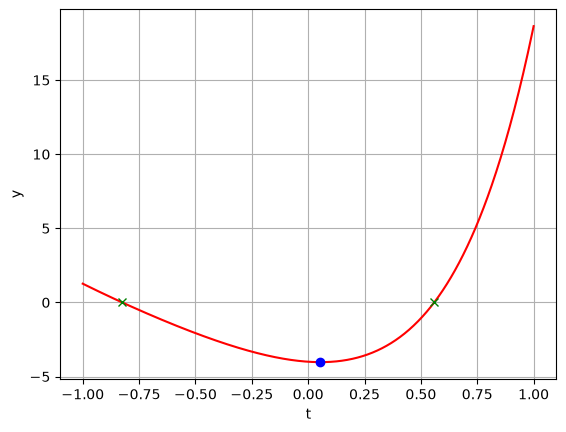

Le minimum se situe en 0.05469 et à comme valeur: -4.028
Les racines de la fonction se situe en: -0.825, 0.559


In [ ]:
def fct(t):
    return (2*t) + (8*np.exp(2*t)) - (17 *np.exp(t)) + 3 + (2*np.exp(-t))

x0 = 0
t_min = fmin(fct,x0)
min = fct(t_min)
x = np.linspace(-1, 1, 1000)
y = fct(x)
t = [-1.0, 0.6]

sol1 = root(fct, t[0])
sol2 = root(fct, t[1])

racines = [sol1.x[0], sol2.x[0]]


plt.plot(x,y,"r-", label="y(t)")
plt.plot(t_min[0],min,"bo",label="Minimum")
plt.plot(racines, [0, 0], "gx", label="Racines")
plt.grid()
plt.xlabel("t")
plt.ylabel("y")
plt.show()
print(f"Le minimum se situe en {t_min[0]:.5f} et à comme valeur: {min[0]:.3f}")
print(f"Les racines de la fonction se situe en: {racines[0]:.3f}, {racines[1]:.3f}")

# Question 2 

![Image circuit](Circuit.png)

- 3 Mailles:
    - 16 = -10000*I1 - 12000*I2
    - 12 = -12000*I2 + 18000*I3
    - 21 = -18000*I3 - 13000*I4
- 3 Noeuds:
    - I1 - I2 - I3 + I4 = 0 
    - -I1 + I2 - I5 = 0
    - I3 - I4 + I5 = 0


In [ ]:
I = np.array([
    [10000,12000,0,0,0],
    [0,12000,-18000,0,0],
    [0,0,18000,13000,0],
    [1,-1,-1,1,0],
    [0,0,1,-1,1]    
])
V = np.transpose(np.array([16,12,21,0,0]))
X = np.linalg.solve(I, V)
# print(I)
# print(V)
# print(X)
# i = 1
# for j in X:
#     print(f"La valeur de I{i} est de {j} A")
#     i+=1
P_dis = 10000*((X[0])**2)
print(f"La puissance dissipée dans la résistance de 10 kOhm est de {(P_dis):.5f}W")

La puissance dissipée dans la résistance de 10 kOhm est de 0.00006W


# Question 3


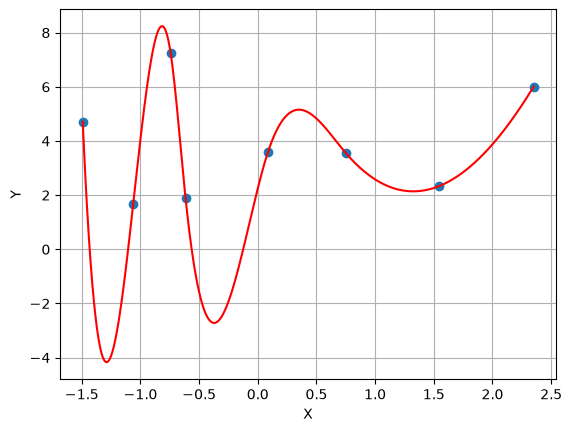

In [10]:
x = np.array([-1.4916, -1.0616, -0.7423, -0.6156,  0.0859,  0.7481,  1.5442,  2.3505])
y = np.array([ 4.7089,  1.6615,  7.2450,  1.9050,  3.5779,  3.5657,  2.3328,  6.0074])

# Affichage de vérification
# print("Array x :", x)
# print("Array y :", y)
x_interp = np.linspace(-1.4916,2.3505, 1000)

f = scint.interp1d(x,y,'cubic')


plt.plot(x, y, "o",label="Nuage de point")
plt.plot(x_interp, f(x_interp),"r-", label="Interpolation spline cubique")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid()
plt.show()

# Question 4

Série de taylor de la fonction sin(x)

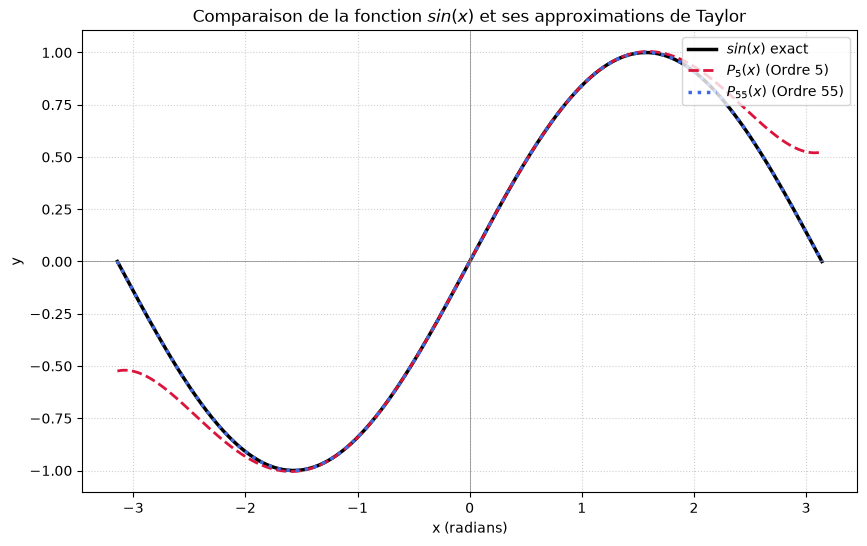

In [11]:
def factorielle(n):
    """Calcule la factorielle d'un entier n."""
    res = 1
    for i in range(1, n + 1):
        res *= i
    return res


def polynome_taylor_sin(ordre, x):
    """Calcule le polynôme de Taylor de sin(x) autour de 0.

    Arguments:
    - ordre : l'ordre maximal (2n + 1)
    - x : la valeur en radians
    """
    if ordre < 0:
        raise ValueError(
            "Erreur critique : L'ordre du développement limité doit être positif."
        )

    # Détermination de 'n' à partir de l'ordre (ordre = 2n + 1)
    n_max = (ordre - 1) // 2

    somme = 0.0
    for i in range(n_max + 1):
        exposant = 2 * i + 1
        signe = (-1) ** i
        terme = signe * (x**exposant) / factorielle(exposant)
        somme += terme
    return somme


# print("--- Test de la gestion des erreurs ---")
# try:
#     valeur = polynome_taylor_sin(ordre=-5, x=1.0)
# except ValueError as e:
#     print(f"Exception interceptée avec succès ! Message : {e}")
# print("--------------------------------------\n")

x_vals = np.linspace(-np.pi, np.pi, 500)


y_exact = np.sin(x_vals)
y_p5 = [polynome_taylor_sin(5, x) for x in x_vals]
y_p55 = [polynome_taylor_sin(55, x) for x in x_vals]

plt.figure(figsize=(10, 6))


plt.plot(x_vals, y_exact, label="$sin(x)$ exact", color="black", linewidth=2.5)
plt.plot(
    x_vals,
    y_p5,
    label="$P_5(x)$ (Ordre 5)",
    color="crimson",
    linestyle="--",
    linewidth=2,
)
plt.plot(
    x_vals,
    y_p55,
    label="$P_{55}(x)$ (Ordre 55)",
    color="royalblue",
    linestyle=":",
    linewidth=2.5,
)

plt.title("Comparaison de la fonction $sin(x)$ et ses approximations de Taylor")
plt.xlabel("x (radians)")
plt.ylabel("y")
plt.axhline(0, color="gray", linewidth=0.5, linestyle="-")
plt.axvline(0, color="gray", linewidth=0.5, linestyle="-")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right")

plt.show()
